In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

DATA_PATH = Path("/Users/arjun/Documents/UAV thesis/uav_px4_dataset_project/processed_10hz/clean_ml_ready_10hz_expanded.csv")

print("Dataset path:", DATA_PATH)
print("File exists:", DATA_PATH.exists())

if not DATA_PATH.exists():
    raise FileNotFoundError(f"File not found: {DATA_PATH}")

df = pd.read_csv(DATA_PATH, low_memory=False)

print("Loaded successfully")
print("Shape:", df.shape)
print("Unique flights:", df["log_id"].nunique())
print("\nDataset label distribution:")
print(df["dataset_label"].value_counts())

display(df.head())


Dataset path: /Users/arjun/Documents/UAV thesis/uav_px4_dataset_project/processed_10hz/clean_ml_ready_10hz_expanded.csv
File exists: True
Loaded successfully
Shape: (1019991, 378)
Unique flights: 172

Dataset label distribution:
dataset_label
normal      719371
abnormal    300620
Name: count, dtype: int64


,log_id,dataset_label,time_td,actuator_outputs__noutputs,actuator_outputs__output[0],actuator_outputs__output[1],actuator_outputs__output[2],actuator_outputs__output[3],actuator_outputs__output[4],actuator_outputs__output[5],...,vehicle_status__usb_connected,vehicle_status__open_drone_id_system_present,vehicle_status__open_drone_id_system_healthy,vehicle_status__parachute_system_present,vehicle_status__parachute_system_healthy,vehicle_status__avoidance_system_required,vehicle_status__avoidance_system_valid,vehicle_status__rc_calibration_in_progress,vehicle_status__calibration_enabled,vehicle_status__pre_flight_checks_pass
0,00209ad8-f7c4-4d6f-839c-af19d8203e9b,normal,0 days 00:00:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,00209ad8-f7c4-4d6f-839c-af19d8203e9b,normal,0 days 00:00:00.100000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,00209ad8-f7c4-4d6f-839c-af19d8203e9b,normal,0 days 00:00:00.200000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,00209ad8-f7c4-4d6f-839c-af19d8203e9b,normal,0 days 00:00:00.300000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,00209ad8-f7c4-4d6f-839c-af19d8203e9b,normal,0 days 00:00:00.400000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [2]:
summary_table = pd.DataFrame({
    "Metric": [
        "Final clean rows",
        "Number of columns",
        "Unique flight logs",
        "Normal rows",
        "Abnormal rows",
        "Normal flight logs",
        "Abnormal flight logs"
    ],
    "Value": [
        df.shape[0],
        df.shape[1],
        df["log_id"].nunique(),
        df[df["dataset_label"] == "normal"].shape[0],
        df[df["dataset_label"] == "abnormal"].shape[0],
        df[df["dataset_label"] == "normal"]["log_id"].nunique(),
        df[df["dataset_label"] == "abnormal"]["log_id"].nunique()
    ]
})

display(summary_table)


,Metric,Value
0,Final clean rows,1019991
1,Number of columns,378
2,Unique flight logs,172
3,Normal rows,719371
4,Abnormal rows,300620
5,Normal flight logs,129
6,Abnormal flight logs,43


In [3]:
important_cols = [
    "log_id",
    "dataset_label",
    "time_s",
    "battery_status__voltage_v",
    "battery_status__current_a",
    "power_w",
    "cumulative_energy_wh",
    "target_energy_next_60s_wh"
]

for col in important_cols:
    print(col, "exists:", col in df.columns)

display(df[important_cols].head())

log_id exists: True
dataset_label exists: True
time_s exists: True
battery_status__voltage_v exists: True
battery_status__current_a exists: True
power_w exists: True
cumulative_energy_wh exists: True
target_energy_next_60s_wh exists: True


,log_id,dataset_label,time_s,battery_status__voltage_v,battery_status__current_a,power_w,cumulative_energy_wh,target_energy_next_60s_wh
0,00209ad8-f7c4-4d6f-839c-af19d8203e9b,normal,0.0,11.763942,0.00000,0.000000,0.000000,0.001262
1,00209ad8-f7c4-4d6f-839c-af19d8203e9b,normal,0.1,11.763942,0.00000,0.000000,0.000000,0.001262
2,00209ad8-f7c4-4d6f-839c-af19d8203e9b,normal,0.2,11.763942,0.00000,0.000000,0.000000,0.001262
3,00209ad8-f7c4-4d6f-839c-af19d8203e9b,normal,0.3,11.763942,0.00000,0.000000,0.000000,0.001262
4,00209ad8-f7c4-4d6f-839c-af19d8203e9b,normal,0.4,11.730804,0.46793,5.489191,0.000152,0.001109


In [4]:
'''Flight level summary to check for balance and zero-current issue'''
current_col = "battery_status__current_a"

flight_summary = (
    df.groupby(["log_id", "dataset_label"])
    .agg(
        rows=("time_s", "count"),
        duration_s=("time_s", "max"),
        mean_voltage_v=("battery_status__voltage_v", "mean"),
        mean_current_a=(current_col, "mean"),
        max_current_a=(current_col, "max"),
        mean_power_w=("power_w", "mean"),
        max_power_w=("power_w", "max"),
        total_energy_wh=("cumulative_energy_wh", "max"),
        mean_target_60s=("target_energy_next_60s_wh", "mean")
    )
    .reset_index()
)

flight_summary["duration_min"] = flight_summary["duration_s"] / 60

display(flight_summary.head())

print("Flight-level summary by label:")
display(
    flight_summary.groupby("dataset_label").agg(
        flights=("log_id", "count"),
        total_rows=("rows", "sum"),
        mean_duration_min=("duration_min", "mean"),
        median_duration_min=("duration_min", "median"),
        mean_power_w=("mean_power_w", "mean"),
        mean_total_energy_wh=("total_energy_wh", "mean"),
        mean_target_60s=("mean_target_60s", "mean")
    )
)

,log_id,dataset_label,rows,duration_s,mean_voltage_v,mean_current_a,max_current_a,mean_power_w,max_power_w,total_energy_wh,mean_target_60s,duration_min
0,00209ad8-f7c4-4d6f-839c-af19d8203e9b,normal,7045,705.6,11.114077,11.876939,30.649393,129.512605,336.18198,25.363426,2.284502,11.760000
1,00a25d12-c11a-46d2-a704-e2abe3fd38c6,abnormal,8214,821.3,27.138708,8.457231,35.394398,221.717570,932.57090,50.588559,3.760646,13.688333
2,022107fb-9d00-47b7-bc42-ea336f7040f3,normal,3553,358.4,10.534156,3.926019,9.176000,41.262665,92.88736,4.090128,0.669733,5.973333
3,0226edf3-a838-48f9-b932-1882f5353d20,normal,13433,1357.7,22.157616,13.638546,52.787110,301.388797,1150.47960,113.103526,4.995802,22.628333
4,0332fefb-a16f-4ff9-b626-e8a158346ff4,normal,3432,369.5,10.760786,14.897819,26.629454,160.178612,282.31830,15.805257,2.564332,6.158333


Flight-level summary by label:


,flights,total_rows,mean_duration_min,median_duration_min,mean_power_w,mean_total_energy_wh,mean_target_60s
dataset_label,,,,,,,
abnormal,43,300620,11.671008,9.510000,195.990479,47.003380,3.294307
normal,129,719371,9.317248,7.248333,120.945066,29.957493,2.024215


In [5]:
'''Check for zero-current and zero-power issues at the flight level'''
zero_stats = (
    df.assign(
        zero_current=df["battery_status__current_a"].abs() < 0.01,
        zero_power=df["power_w"].abs() < 0.01
    )
    .groupby(["log_id", "dataset_label"])
    .agg(
        zero_current_percent=("zero_current", "mean"),
        zero_power_percent=("zero_power", "mean")
    )
    .reset_index()
)

zero_stats["zero_current_percent"] *= 100
zero_stats["zero_power_percent"] *= 100

flight_summary = flight_summary.merge(
    zero_stats,
    on=["log_id", "dataset_label"],
    how="left"
)

print("Zero-current / zero-power summary:")
display(
    flight_summary.groupby("dataset_label").agg(
        mean_zero_current_percent=("zero_current_percent", "mean"),
        mean_zero_power_percent=("zero_power_percent", "mean"),
        max_zero_current_percent=("zero_current_percent", "max"),
        max_zero_power_percent=("zero_power_percent", "max")
    )
)

print("Flights with highest zero-current percentage:")
display(
    flight_summary.sort_values("zero_current_percent", ascending=False).head(15)
)

Zero-current / zero-power summary:


,mean_zero_current_percent,mean_zero_power_percent,max_zero_current_percent,max_zero_power_percent
dataset_label,,,,
abnormal,5.211535,5.211535,68.754066,68.754066
normal,18.307764,18.307764,83.818505,83.818505


Flights with highest zero-current percentage:


,log_id,dataset_label,rows,duration_s,mean_voltage_v,mean_current_a,max_current_a,mean_power_w,max_power_w,total_energy_wh,mean_target_60s,duration_min,zero_current_percent,zero_power_percent
39,26b35349-c4de-4a1c-b1ff-9c625c531058,normal,7317,732.3,15.066905,1.355332,21.340399,19.508964,297.223500,3.968030,0.268932,12.205000,83.818505,83.818505
89,7dd21702-66c6-4fe8-bd41-c45264c5fdaa,normal,6105,610.4,11.200944,0.056408,0.682000,0.631332,7.473175,0.107063,0.010579,10.173333,72.285012,72.285012
114,a3363780-8647-4341-a38a-77176235cdf2,abnormal,6148,618.5,22.371507,0.028541,0.409200,0.638870,9.146930,0.109451,0.010759,10.308333,68.754066,68.754066
62,4bdbe202-60fc-42a0-9818-3b88a24b69c2,normal,5993,599.2,11.195494,0.111902,0.905200,1.253351,10.203408,0.208648,0.020800,9.986667,63.056900,63.056900
59,42b57f46-f2fe-45a4-8a31-928db553fb28,normal,23914,2391.3,11.455389,1.946374,14.904799,20.975595,156.079150,13.933621,0.349593,39.855000,60.161412,60.161412
105,93080fe8-3f6a-4c60-bb9c-60e7b215ea58,normal,4437,450.4,12.757186,0.070988,0.471200,0.919969,5.965335,0.114195,0.015613,7.506667,58.057246,58.057246
150,ddfe66ac-3277-4542-85ff-e52578e0fee6,normal,11942,1195.3,16.024560,5.165603,29.394493,79.066145,432.905330,26.250323,1.402184,19.921667,57.896500,57.896500
166,ee406c38-9a79-43e2-ad2f-ade2e8e413da,normal,4768,478.3,11.229886,1.145822,4.935200,10.957073,54.045544,1.454284,0.183449,7.971667,50.964765,50.964765
102,88f7d5ba-9eda-4e38-85ef-00d869562cab,normal,4761,476.0,10.890735,1.191627,5.555200,11.290450,58.040916,1.493162,0.187821,7.933333,50.661626,50.661626
148,dacae7b8-bb2b-4b83-ab0d-23211e9a2814,normal,4864,486.3,11.377369,0.957645,4.079600,9.505153,44.358986,1.284252,0.156678,8.105000,49.732730,49.732730


In [19]:
'''missing summary'''
missing_summary = pd.DataFrame({
    "column": df.columns,
    "missing_count": df.isna().sum().values,
    "missing_percent": (df.isna().sum().values / len(df)) * 100
}).sort_values("missing_percent", ascending=False)

display(missing_summary.head(100))

,column,missing_count,missing_percent
377,vehicle_status__pre_flight_checks_pass,1019991,100.0
350,vehicle_gps_position__selected_rtcm_instance,1019991,100.0
201,vehicle_air_data__time_td,1019991,100.0
200,vehicle_air_data__rho,1019991,100.0
199,vehicle_air_data__baro_pressure_pa,1019991,100.0
...,...,...,...
339,vehicle_angular_velocity__xyz_derivative[2],1019991,100.0
340,vehicle_gps_position__timestamp_sample,1019991,100.0
341,vehicle_gps_position__latitude_deg,1019991,100.0
342,vehicle_gps_position__longitude_deg,1019991,100.0


In [45]:
high_missing_cols = missing_summary[
    missing_summary["missing_percent"] >= 80
]["column"].tolist()

print("Columns with >=80% missing:", len(high_missing_cols))

display(
    missing_summary[
        missing_summary["missing_percent"] >= 80
    ].head(100)
)

Columns with >=80% missing: 342


,column,missing_count,missing_percent
377,vehicle_status__pre_flight_checks_pass,1019991,100.0
350,vehicle_gps_position__selected_rtcm_instance,1019991,100.0
201,vehicle_air_data__time_td,1019991,100.0
200,vehicle_air_data__rho,1019991,100.0
199,vehicle_air_data__baro_pressure_pa,1019991,100.0
...,...,...,...
339,vehicle_angular_velocity__xyz_derivative[2],1019991,100.0
340,vehicle_gps_position__timestamp_sample,1019991,100.0
341,vehicle_gps_position__latitude_deg,1019991,100.0
342,vehicle_gps_position__longitude_deg,1019991,100.0


In [60]:
main_cols = [
   "log_id",
    "dataset_label",
    "time_td",
    "time_s",
    "battery_status__voltage_v",
    "battery_status__voltage_filtered_v",
    "battery_status__current_a",
    "power_w",
    "energy_increment_wh",
    "cumulative_energy_wh",
    "future_cumulative_energy_wh",
    "target_energy_next_60s_wh"
]

main_missing_summary = pd.DataFrame({
    "column": main_cols,
    "exists": [col in df.columns for col in main_cols],
    "missing_count": [
        df[col].isna().sum() if col in df.columns else None
        for col in main_cols
    ],
    "missing_percent": [
        (df[col].isna().mean() * 100) if col in df.columns else None
        for col in main_cols
    ]
})

display(main_missing_summary)

,column,exists,missing_count,missing_percent
0,log_id,True,0,0.0
1,dataset_label,True,0,0.0
2,time_td,True,0,0.0
3,time_s,True,0,0.0
4,battery_status__voltage_v,True,0,0.0
5,battery_status__voltage_filtered_v,True,0,0.0
6,battery_status__current_a,True,0,0.0
7,power_w,True,0,0.0
8,energy_increment_wh,True,0,0.0
9,cumulative_energy_wh,True,0,0.0


In [59]:
battery_related_cols = [
    col for col in df.columns
    if "battery_status" in col.lower()
    or "power" in col.lower()
    or "energy" in col.lower()
    or "current" in col.lower()
    or "voltage" in col.lower()
    or "remaining" in col.lower()
    or "discharged" in col.lower()
]

battery_missing_summary = pd.DataFrame({
    "column": battery_related_cols,
    "missing_count": df[battery_related_cols].isna().sum().values,
    "missing_percent": (df[battery_related_cols].isna().sum().values / len(df)) * 100
}).sort_values("missing_percent", ascending=False)

display(battery_missing_summary)

,column,missing_count,missing_percent
98,vehicle_status__power_input_valid,1019991,100.0
93,battery_status_1__voltage_cell_v[8],1019991,100.0
60,battery_status__time_remaining_s,1019991,100.0
89,battery_status_1__voltage_cell_v[4],1019991,100.0
90,battery_status_1__voltage_cell_v[5],1019991,100.0
...,...,...,...
12,energy_increment_wh,0,0.0
13,cumulative_energy_wh,0,0.0
14,future_cumulative_energy_wh,0,0.0
1,battery_status__voltage_filtered_v,0,0.0


In [ ]:
'''Check for time gaps between consecutive rows within each flight log'''
gap_df = df.sort_values(["log_id", "time_s"]).copy()

gap_df["time_gap"] = gap_df.groupby("log_id")["time_s"].diff()

gap_summary = (
    gap_df.groupby("log_id")["time_gap"]
    .agg(
        mean_gap="mean",
        median_gap="median",
        max_gap="max",
        gap_std="std"
    )
    .reset_index()
)

display(gap_summary.describe())

large_gaps = gap_summary[gap_summary["max_gap"] > 0.2]

print("Flights with max gap greater than 0.2 seconds:", len(large_gaps))
display(large_gaps.head(20))

,mean_gap,median_gap,max_gap,gap_std
count,172.000000,1.720000e+02,172.000000,1.720000e+02
mean,0.100265,1.000000e-01,0.454651,8.096798e-03
std,0.000685,1.024116e-14,0.658042,1.298026e-02
min,0.100000,1.000000e-01,0.100000,9.007156e-15
25%,0.100000,1.000000e-01,0.100000,1.991073e-14
50%,0.100000,1.000000e-01,0.100000,8.320126e-14
75%,0.100272,1.000000e-01,0.500000,1.087522e-02
max,0.107695,1.000000e-01,6.700000,1.005479e-01


Flights with max gap greater than 0.2 seconds: 84


,log_id,mean_gap,median_gap,max_gap,gap_std
0,00209ad8-f7c4-4d6f-839c-af19d8203e9b,0.100170,0.1,0.5,0.008254
2,022107fb-9d00-47b7-bc42-ea336f7040f3,0.100901,0.1,0.5,0.018964
3,0226edf3-a838-48f9-b932-1882f5353d20,0.101080,0.1,1.0,0.027059
4,0332fefb-a16f-4ff9-b626-e8a158346ff4,0.107695,0.1,2.5,0.100548
5,03a4237b-52e2-4327-8bfd-0f6e4d6de940,0.102108,0.1,1.5,0.050344
6,03d4d195-b9d6-4b8e-8906-7d399aa01d1e,0.100876,0.1,1.0,0.023449
7,043709f7-fb65-4b43-b4e7-144d59c14e95,0.100418,0.1,0.5,0.012922
8,06b760bf-d457-46b7-84e1-f08c180aefb3,0.100325,0.1,2.0,0.024848
9,08aab983-e7b7-41b0-a3fe-c719f68cc230,0.100514,0.1,1.5,0.022440
10,097caeda-db01-421c-a7a3-fe17eedc1b71,0.100180,0.1,0.5,0.008494


In [ ]:
'''Battery and energy descriptive statistics'''
battery_energy_cols = [
    "battery_status__voltage_v",
    "battery_status__current_a",
    "power_w",
    "cumulative_energy_wh",
    "target_energy_next_60s_wh"
]

display(df[battery_energy_cols].describe().T)

,count,mean,std,min,25%,50%,75%,max
battery_status__voltage_v,1019991.0,15.046909,7.832548,5.715733,11.099970,11.899337,15.486239,54.334470
battery_status__current_a,1019991.0,10.455675,13.336189,-38.292480,0.437472,7.705900,15.206699,161.003130
power_w,1019991.0,207.583978,487.777479,0.000000,7.251712,95.366510,191.228210,7732.615700
cumulative_energy_wh,1019991.0,38.224749,166.037378,0.000000,0.935796,5.083365,17.642091,1920.082213
target_energy_next_60s_wh,1019991.0,3.486437,8.041473,0.000000,0.278390,1.753726,3.214515,66.087665


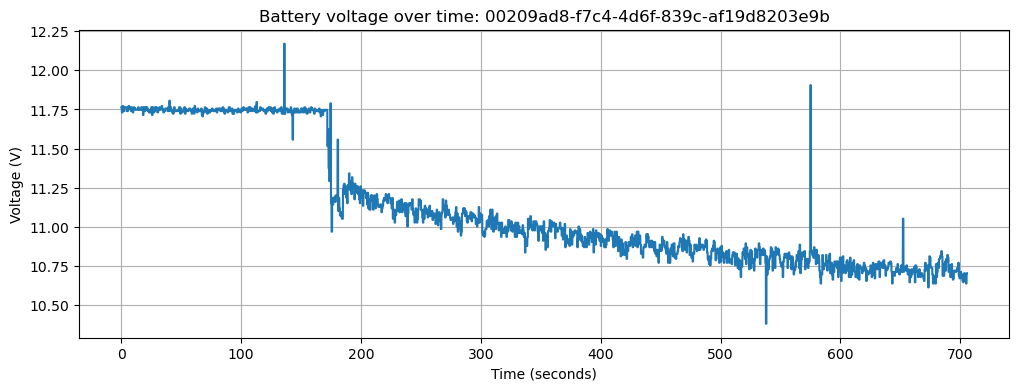

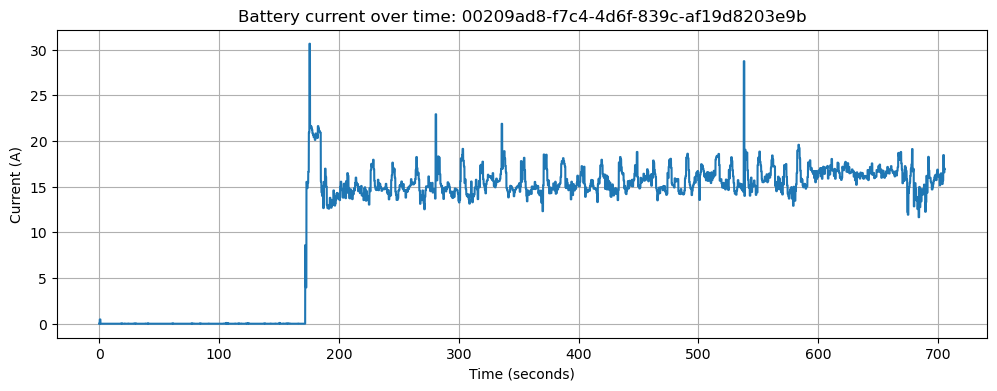

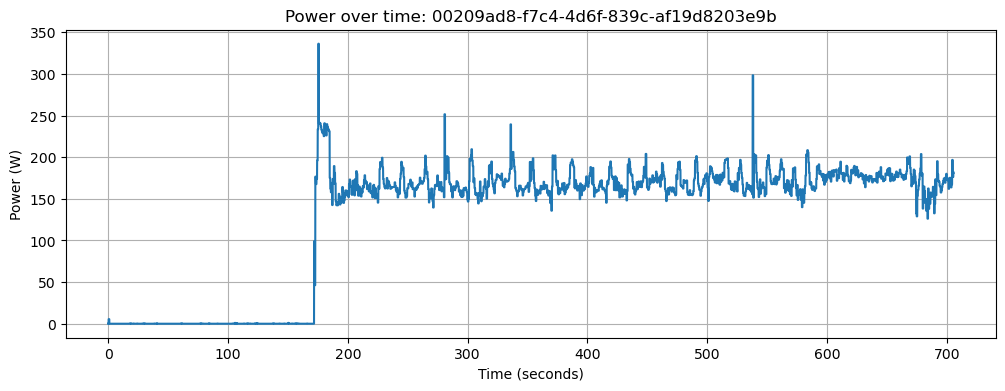

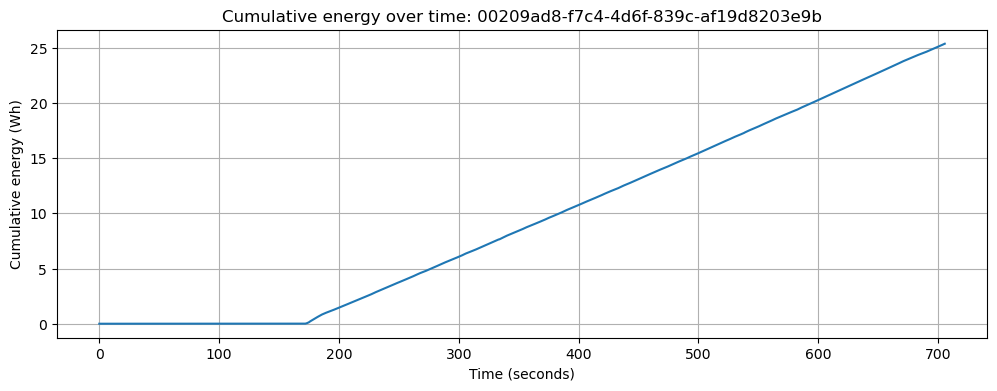

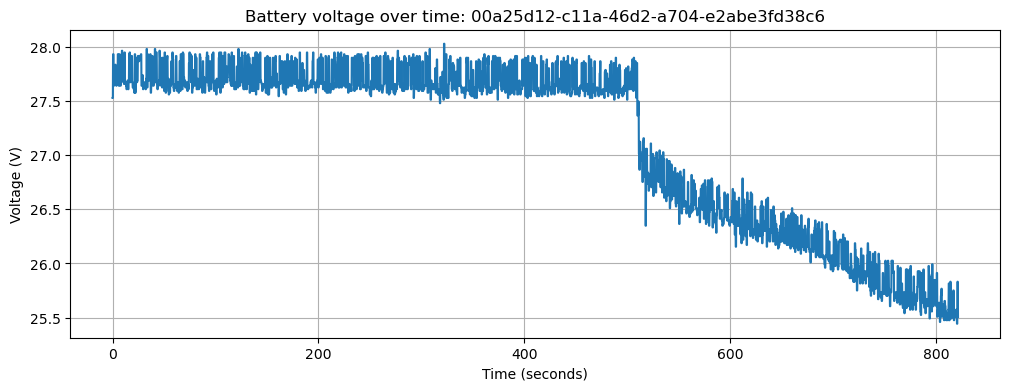

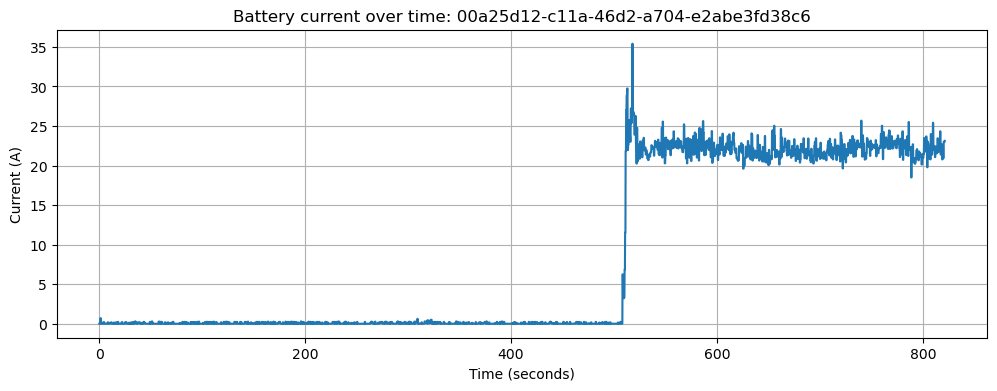

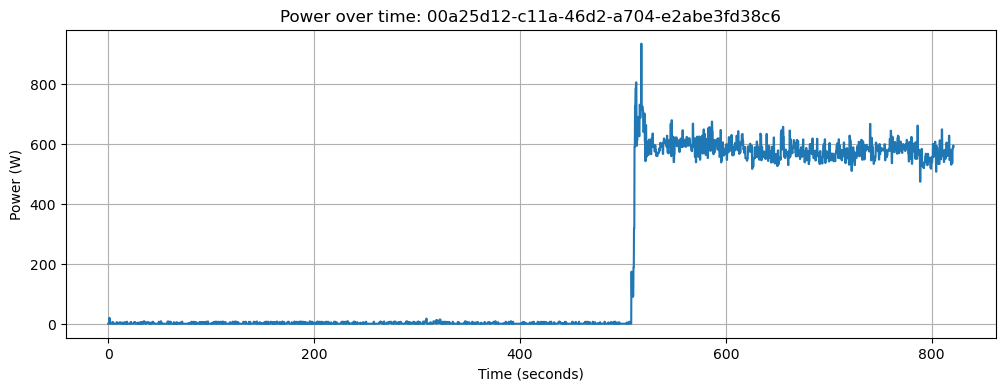

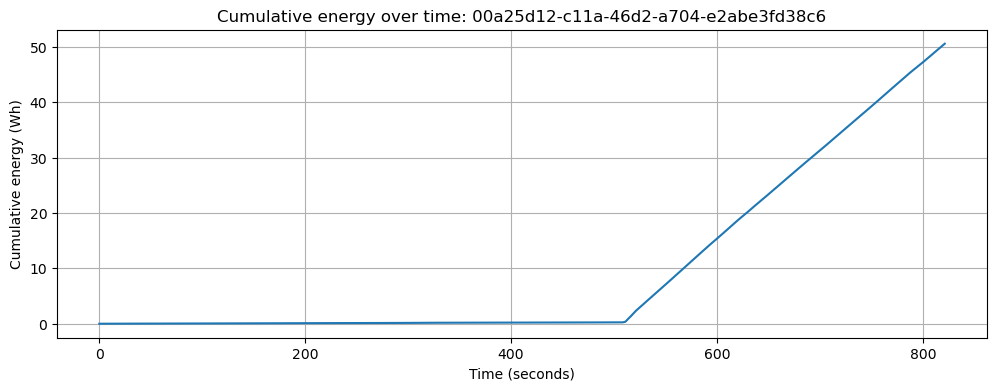

In [ ]:
'''Visualize battery voltage, current, power, and cumulative energy over time for a few sample flights'''
normal_flight = df[df["dataset_label"] == "normal"]["log_id"].iloc[0]
abnormal_flight = df[df["dataset_label"] == "abnormal"]["log_id"].iloc[0]

for flight_id in [normal_flight, abnormal_flight]:
    temp = df[df["log_id"] == flight_id].sort_values("time_s")

    plt.figure(figsize=(12, 4))
    plt.plot(temp["time_s"], temp["battery_status__voltage_v"])
    plt.xlabel("Time (seconds)")
    plt.ylabel("Voltage (V)")
    plt.title(f"Battery voltage over time: {flight_id}")
    plt.grid(True)
    plt.show()

    plt.figure(figsize=(12, 4))
    plt.plot(temp["time_s"], temp["battery_status__current_a"])
    plt.xlabel("Time (seconds)")
    plt.ylabel("Current (A)")
    plt.title(f"Battery current over time: {flight_id}")
    plt.grid(True)
    plt.show()

    plt.figure(figsize=(12, 4))
    plt.plot(temp["time_s"], temp["power_w"])
    plt.xlabel("Time (seconds)")
    plt.ylabel("Power (W)")
    plt.title(f"Power over time: {flight_id}")
    plt.grid(True)
    plt.show()

    plt.figure(figsize=(12, 4))
    plt.plot(temp["time_s"], temp["cumulative_energy_wh"])
    plt.xlabel("Time (seconds)")
    plt.ylabel("Cumulative energy (Wh)")
    plt.title(f"Cumulative energy over time: {flight_id}")
    plt.grid(True)
    plt.show()

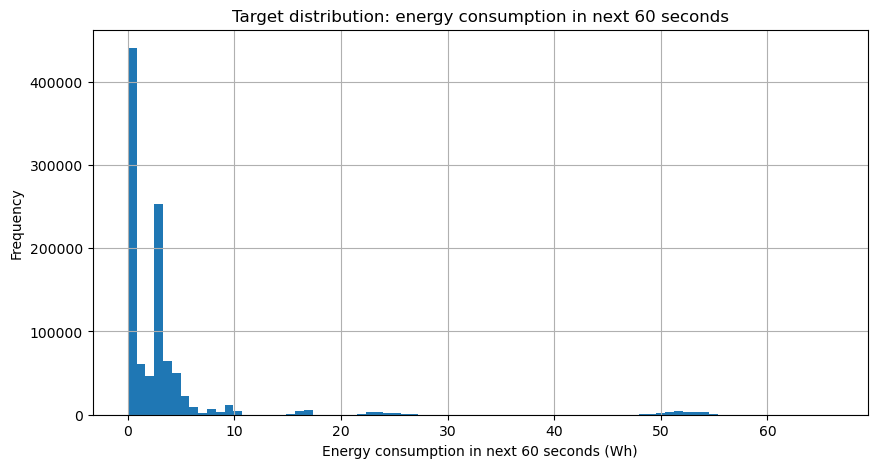

count    1.019991e+06
mean     3.486437e+00
std      8.041473e+00
min      0.000000e+00
25%      2.783899e-01
50%      1.753726e+00
75%      3.214515e+00
max      6.608766e+01
Name: target_energy_next_60s_wh, dtype: float64

In [ ]:
plt.figure(figsize=(10, 5))
plt.hist(df["target_energy_next_60s_wh"].dropna(), bins=80)
plt.xlabel("Energy consumption in next 60 seconds (Wh)")
plt.ylabel("Frequency")
plt.title("Target distribution: energy consumption in next 60 seconds")
plt.grid(True)
plt.show()

display(df["target_energy_next_60s_wh"].describe())

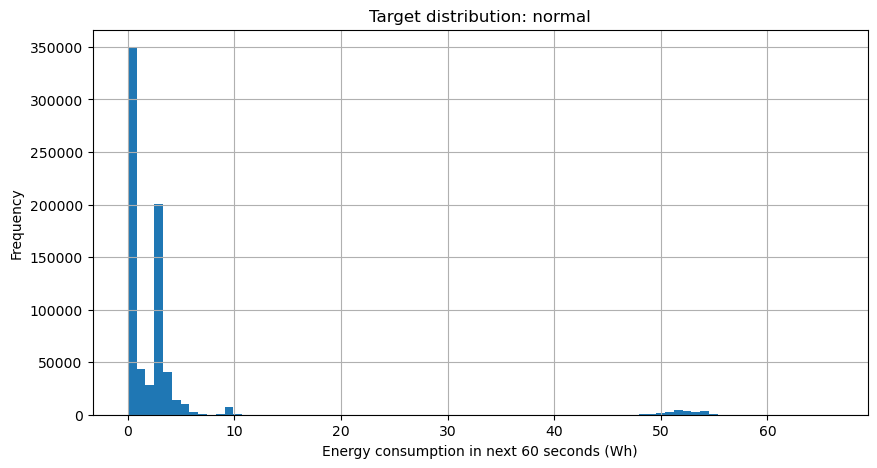

normal


count    719371.000000
mean          3.242235
std           8.904512
min           0.000000
25%           0.277931
50%           0.932768
75%           3.070563
max          66.087665
Name: target_energy_next_60s_wh, dtype: float64

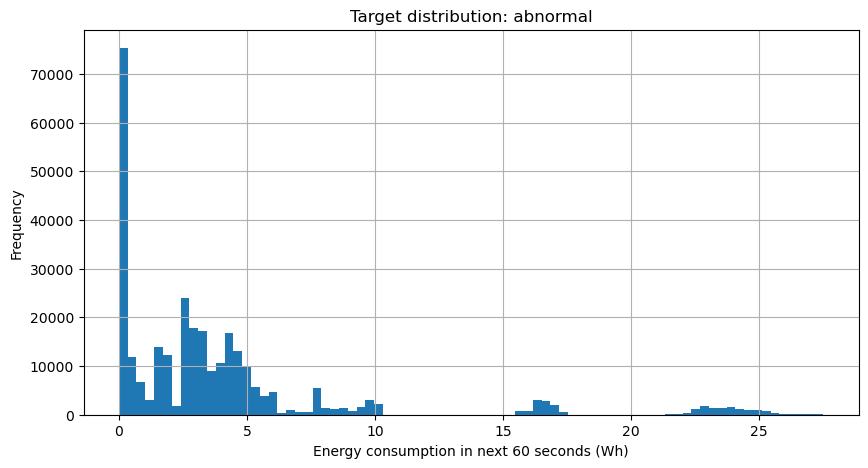

abnormal


count    300620.000000
mean          4.070803
std           5.402232
min           0.000000
25%           0.322849
50%           2.775983
75%           4.656494
max          27.502023
Name: target_energy_next_60s_wh, dtype: float64

In [ ]:
'''Target distribution'''
for label in df["dataset_label"].unique():
    temp = df[df["dataset_label"] == label]

    plt.figure(figsize=(10, 5))
    plt.hist(temp["target_energy_next_60s_wh"].dropna(), bins=80)
    plt.xlabel("Energy consumption in next 60 seconds (Wh)")
    plt.ylabel("Frequency")
    plt.title(f"Target distribution: {label}")
    plt.grid(True)
    plt.show()

    print(label)
    display(temp["target_energy_next_60s_wh"].describe())

In [ ]:
'''Correlation with target'''
numeric_df = df.select_dtypes(include=[np.number]).copy()

corr = numeric_df.corr(numeric_only=True)["target_energy_next_60s_wh"].sort_values(ascending=False)

print("Top positive correlations with target:")
display(corr.head(25))

print("Top negative correlations with target:")
display(corr.tail(25))

Top positive correlations with target:


target_energy_next_60s_wh               1.000000
battery_status_1__system_source         0.994545
battery_status_1__cell_count            0.984897
energy_increment_wh                     0.983808
power_w                                 0.983808
battery_status__current_average_a       0.976117
battery_status_1__voltage_filtered_v    0.953036
battery_status_1__voltage_v             0.953023
battery_status__serial_number           0.911174
battery_status_1__connected             0.891357
battery_status__current_filtered_a      0.855312
battery_status__current_a               0.848089
future_cumulative_energy_wh             0.843589
cumulative_energy_wh                    0.829338
battery_status__discharged_mah          0.806500
battery_status__cell_count              0.748855
battery_status__voltage_filtered_v      0.706920
battery_status__voltage_v               0.701898
battery_status__voltage_cell_v[4]       0.561947
battery_status__voltage_cell_v[5]       0.561947
battery_status_1__sc

Top negative correlations with target:


vehicle_local_position__heading_var            NaN
vehicle_local_position__unaided_heading        NaN
vehicle_local_position__tilt_var               NaN
vehicle_local_position__dead_reckoning         NaN
vehicle_status__valid_nav_states_mask          NaN
vehicle_status__can_set_nav_states_mask        NaN
vehicle_status__nav_state_user_intention       NaN
vehicle_status__executor_in_charge             NaN
vehicle_status__failsafe_and_user_took_over    NaN
vehicle_status__failsafe_defer_state           NaN
vehicle_status__gcs_connection_lost            NaN
vehicle_status__gcs_connection_lost_counter    NaN
vehicle_status__safety_button_available        NaN
vehicle_status__safety_off                     NaN
vehicle_status__power_input_valid              NaN
vehicle_status__usb_connected                  NaN
vehicle_status__open_drone_id_system_present   NaN
vehicle_status__open_drone_id_system_healthy   NaN
vehicle_status__parachute_system_present       NaN
vehicle_status__parachute_syste

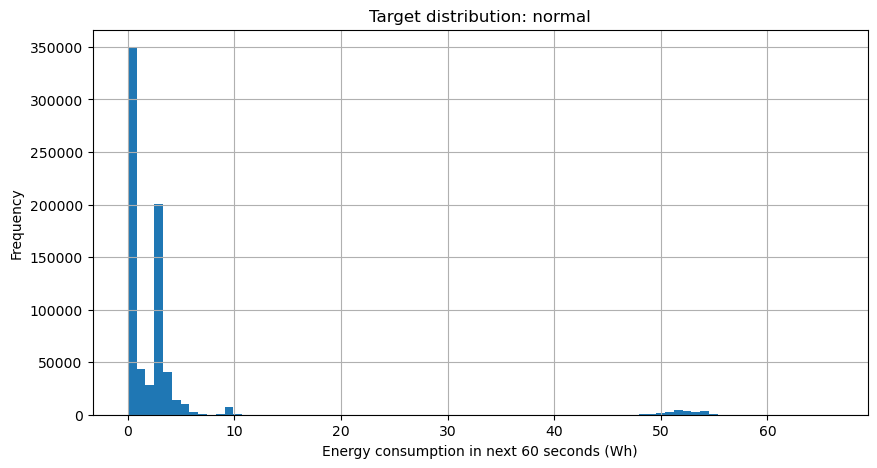

normal


count    719371.000000
mean          3.242235
std           8.904512
min           0.000000
25%           0.277931
50%           0.932768
75%           3.070563
max          66.087665
Name: target_energy_next_60s_wh, dtype: float64

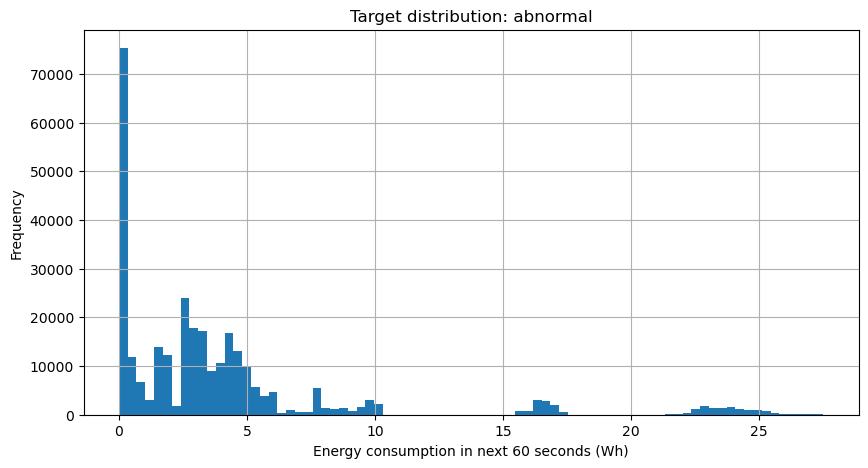

abnormal


count    300620.000000
mean          4.070803
std           5.402232
min           0.000000
25%           0.322849
50%           2.775983
75%           4.656494
max          27.502023
Name: target_energy_next_60s_wh, dtype: float64

Top positive correlations with target:


target_energy_next_60s_wh               1.000000
battery_status_1__system_source         0.994545
battery_status_1__cell_count            0.984897
energy_increment_wh                     0.983808
power_w                                 0.983808
battery_status__current_average_a       0.976117
battery_status_1__voltage_filtered_v    0.953036
battery_status_1__voltage_v             0.953023
battery_status__serial_number           0.911174
battery_status_1__connected             0.891357
battery_status__current_filtered_a      0.855312
battery_status__current_a               0.848089
future_cumulative_energy_wh             0.843589
cumulative_energy_wh                    0.829338
battery_status__discharged_mah          0.806500
battery_status__cell_count              0.748855
battery_status__voltage_filtered_v      0.706920
battery_status__voltage_v               0.701898
battery_status__voltage_cell_v[4]       0.561947
battery_status__voltage_cell_v[5]       0.561947
battery_status_1__sc

Top negative correlations with target:


vehicle_local_position__heading_var            NaN
vehicle_local_position__unaided_heading        NaN
vehicle_local_position__tilt_var               NaN
vehicle_local_position__dead_reckoning         NaN
vehicle_status__valid_nav_states_mask          NaN
vehicle_status__can_set_nav_states_mask        NaN
vehicle_status__nav_state_user_intention       NaN
vehicle_status__executor_in_charge             NaN
vehicle_status__failsafe_and_user_took_over    NaN
vehicle_status__failsafe_defer_state           NaN
vehicle_status__gcs_connection_lost            NaN
vehicle_status__gcs_connection_lost_counter    NaN
vehicle_status__safety_button_available        NaN
vehicle_status__safety_off                     NaN
vehicle_status__power_input_valid              NaN
vehicle_status__usb_connected                  NaN
vehicle_status__open_drone_id_system_present   NaN
vehicle_status__open_drone_id_system_healthy   NaN
vehicle_status__parachute_system_present       NaN
vehicle_status__parachute_syste

In [ ]:
'''Target distribution by normal/abnormal'''
for label in df["dataset_label"].unique():
    temp = df[df["dataset_label"] == label]

    plt.figure(figsize=(10, 5))
    plt.hist(temp["target_energy_next_60s_wh"].dropna(), bins=80)
    plt.xlabel("Energy consumption in next 60 seconds (Wh)")
    plt.ylabel("Frequency")
    plt.title(f"Target distribution: {label}")
    plt.grid(True)
    plt.show()

    print(label)
    display(temp["target_energy_next_60s_wh"].describe())

numeric_df = df.select_dtypes(include=[np.number]).copy()

corr = numeric_df.corr(numeric_only=True)["target_energy_next_60s_wh"].sort_values(ascending=False)

print("Top positive correlations with target:")
display(corr.head(25))

print("Top negative correlations with target:")
display(corr.tail(25))

In [ ]:
'''Outlier report'''
numeric_cols = df.select_dtypes(include=[np.number]).columns

outlier_report = []

for col in numeric_cols:
    series = df[col].dropna()

    if len(series) == 0:
        continue

    q1 = series.quantile(0.25)
    q3 = series.quantile(0.75)
    iqr = q3 - q1

    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr

    outlier_count = ((series < lower) | (series > upper)).sum()

    outlier_report.append({
        "column": col,
        "outlier_count": outlier_count,
        "outlier_percent": (outlier_count / len(series)) * 100,
        "min": series.min(),
        "max": series.max()
    })

outlier_df = pd.DataFrame(outlier_report).sort_values("outlier_percent", ascending=False)

display(outlier_df.head(40))

,column,outlier_count,outlier_percent,min,max
46,battery_status_1__voltage_filtered_v,47094,24.735673,0.000000,49.937523
49,battery_status_1__discharged_mah,47094,24.735673,0.000000,4577.391000
47,battery_status_1__current_a,47094,24.735673,-1.000000,30.765001
48,battery_status_1__current_filtered_a,47094,24.735673,0.000000,20.180204
45,battery_status_1__voltage_v,47094,24.735673,0.000000,49.945614
50,battery_status_1__remaining,46999,24.685775,0.000000,1.000000
51,battery_status_1__scale,46638,24.496163,1.000000,1.264760
73,battery_status__voltage_cell_v[0],57423,20.367966,0.000000,4.350765
75,battery_status__voltage_cell_v[2],57423,20.367966,0.000000,4.350765
76,battery_status__voltage_cell_v[3],57423,20.367966,0.000000,4.350765


In [ ]:
'''Leakage-safe split by flight log'''

from sklearn.model_selection import train_test_split

unique_flights = df[["log_id", "dataset_label"]].drop_duplicates()

print("Unique flights by label:")
display(unique_flights["dataset_label"].value_counts())

train_flights, temp_flights = train_test_split(
    unique_flights,
    test_size=0.30,
    random_state=42,
    stratify=unique_flights["dataset_label"]
)

val_flights, test_flights = train_test_split(
    temp_flights,
    test_size=0.50,
    random_state=42,
    stratify=temp_flights["dataset_label"]
)

train_df = df[df["log_id"].isin(train_flights["log_id"])].copy()
val_df = df[df["log_id"].isin(val_flights["log_id"])].copy()
test_df = df[df["log_id"].isin(test_flights["log_id"])].copy()

print("Train rows:", train_df.shape)
print("Validation rows:", val_df.shape)
print("Test rows:", test_df.shape)

print("\nTrain flights:", train_df["log_id"].nunique())
print("Validation flights:", val_df["log_id"].nunique())
print("Test flights:", test_df["log_id"].nunique())

print("\nFlight label distribution:")
display(pd.DataFrame({
    "train": train_flights["dataset_label"].value_counts(),
    "validation": val_flights["dataset_label"].value_counts(),
    "test": test_flights["dataset_label"].value_counts()
}))

Unique flights by label:


dataset_label
normal      129
abnormal     43
Name: count, dtype: int64

Train rows: (631004, 378)
Validation rows: (185751, 378)
Test rows: (203236, 378)

Train flights: 120
Validation flights: 26
Test flights: 26

Flight label distribution:


,train,validation,test
dataset_label,,,
normal,90,20,19
abnormal,30,6,7


In [ ]:
'''data leakage check'''
train_ids = set(train_df["log_id"])
val_ids = set(val_df["log_id"])
test_ids = set(test_df["log_id"])

print("Train-Val overlap:", len(train_ids.intersection(val_ids)))
print("Train-Test overlap:", len(train_ids.intersection(test_ids)))
print("Val-Test overlap:", len(val_ids.intersection(test_ids)))

Train-Val overlap: 0
Train-Test overlap: 0
Val-Test overlap: 0


In [ ]:
'''Save train, validation, and test split files'''
SPLIT_DIR = Path("/Users/arjun/Documents/UAV thesis/uav_px4_dataset_project/splits")
SPLIT_DIR.mkdir(exist_ok=True)

train_df.to_csv(SPLIT_DIR / "train_df_log_split.csv", index=False)
val_df.to_csv(SPLIT_DIR / "val_df_log_split.csv", index=False)
test_df.to_csv(SPLIT_DIR / "test_df_log_split.csv", index=False)

train_flights.to_csv(SPLIT_DIR / "train_log_ids.csv", index=False)
val_flights.to_csv(SPLIT_DIR / "val_log_ids.csv", index=False)
test_flights.to_csv(SPLIT_DIR / "test_log_ids.csv", index=False)

print("Saved train, validation, and test split files to:")
print(SPLIT_DIR)

Saved train, validation, and test split files to:
/Users/arjun/Documents/UAV thesis/uav_px4_dataset_project/splits


In [61]:
battery_remaining_cols = [
    col for col in df.columns
    if "remaining" in col.lower()
    or "discharged" in col.lower()
    or "capacity" in col.lower()
]

battery_remaining_cols

['battery_status__discharged_mah',
 'battery_status__remaining',
 'battery_status_1__discharged_mah',
 'battery_status_1__remaining',
 'battery_status__capacity',
 'battery_status_1__capacity',
 'battery_status__time_remaining_s',
 'battery_status__full_charge_capacity_wh',
 'battery_status__remaining_capacity_wh',
 'battery_status__design_capacity',
 'battery_status__remaining_capacity']

In [62]:
remaining_report = pd.DataFrame({
    "column": battery_remaining_cols,
    "missing_count": df[battery_remaining_cols].isna().sum().values,
    "missing_percent": (df[battery_remaining_cols].isna().sum().values / len(df)) * 100
}).sort_values("missing_percent")

display(remaining_report)

,column,missing_count,missing_percent
0,battery_status__discharged_mah,0,0.000000
1,battery_status__remaining,0,0.000000
4,battery_status__capacity,381132,37.366212
2,battery_status_1__discharged_mah,829602,81.334247
3,battery_status_1__remaining,829602,81.334247
5,battery_status_1__capacity,886635,86.925767
9,battery_status__design_capacity,974871,95.576432
7,battery_status__full_charge_capacity_wh,977986,95.881826
8,battery_status__remaining_capacity_wh,977986,95.881826
10,battery_status__remaining_capacity,1016876,99.694605


In [57]:
'''Save EDA summary tables'''

SPLIT_DIR = Path("/Users/arjun/Documents/UAV thesis/uav_px4_dataset_project/splits")
SPLIT_DIR.mkdir(exist_ok=True)

train_df.to_csv(SPLIT_DIR / "train_df_log_split.csv", index=False)
val_df.to_csv(SPLIT_DIR / "val_df_log_split.csv", index=False)
test_df.to_csv(SPLIT_DIR / "test_df_log_split.csv", index=False)

train_flights.to_csv(SPLIT_DIR / "train_log_ids.csv", index=False)
val_flights.to_csv(SPLIT_DIR / "val_log_ids.csv", index=False)
test_flights.to_csv(SPLIT_DIR / "test_log_ids.csv", index=False)

print("Saved train, validation, and test split files to:")
print(SPLIT_DIR)
missing_summary.to_csv(EDA_DIR / "missing_value_summary.csv", index=False)
gap_summary.to_csv(EDA_DIR / "time_gap_summary.csv", index=False)
outlier_df.to_csv(EDA_DIR / "outlier_report.csv", index=False)

print("EDA summary tables saved to:")
print(EDA_DIR)

Saved train, validation, and test split files to:
/Users/arjun/Documents/UAV thesis/uav_px4_dataset_project/splits


NameError: name 'EDA_DIR' is not defined